# TADQA results

The table and figure calculate the latest complete 403-question runs directly
from each model's result log using the same shared scorer as the CLI.
An incomplete latest run is marked **Pending** with blank counts and metrics;
no historical or partial-run score is substituted.
The selected scoring view is **source_reviewed (post hoc)**. Existing source
annotations address flagged benchmark mismatches; accepted claims have not all
been independently source-audited.


## Inputs and checks

Both TADQA notebooks use the shared run selection in
[`scripts/reviewer_tatdqa.py`](../scripts/reviewer_tatdqa.py):

- Claude Haiku 4.5: `results/new_submissions/tatdqa_haiku_4_5/results.jsonl`
- Qwen2.5 7B: `results/new_submissions/tatdqa_qwen2.5_7b/results.jsonl`
- Qwen3 30B: `results/new_submissions/tatdqa_qwen3_30b/results.jsonl`
- Llama 3.1 8B: `results/new_submissions/tatdqa_llama3.1_8b/results.jsonl`
- GPT-5.5 via OpenAI API: `results/new_submissions/tatdqa_gpt5.5/results.jsonl`
- Fin-o1 8B: `results/new_submissions/tatdqa_fin_o1_8b/results.jsonl`

Run all cells again to refresh progress and scores from these files. A model is
scored only when its latest log contains all 403 dataset IDs. A valid incomplete
log is displayed as Pending, with its completed-question count and blank metrics.
The scorer validates IDs, question and gold alignment, units, and the existing
source annotations. Unknown IDs, conflicting duplicates, or logs changed during
scoring stop execution. No cached score table supplies these results.

Run top to bottom with the notebook dependencies installed. No model or network
calls are made. Generated exports are written under `paper/`.


The selected Haiku log includes one targeted verifier repair on the original
candidate; the other 402 records retain their original decisions. Its fair-value
case changed to VIOLATED. The [Haiku replacement](../results/new_submissions/tatdqa_haiku_4_5/result_replacements.json)
records the backup, exact result hashes and runtime provenance. GPT-5.5 is the
selected GPT model; the archived GPT-6.1 run is excluded from these tables and
figures.

Fin-o1's KEMET question (`tatdqa_db13c923de59ca7f6a80f93f38f3ef17`) was
rerun once after its original false accept was audited, using the same model,
question, evidence and settings, with no reference-answer feedback or scorer
change. The rerun repeated **58.77%** but returned **ABSTAIN**
(`generic_operation_authority_unresolved`); it did not generate the correct
**−140.12%** answer. The complete new record replaced the original record, and
the other 402 records are byte-identical. The original run had **1 FA and 102
abstentions**; this combined log has **0 FA and 103 abstentions**. The
[Fin-o1 replacement record](../results/new_submissions/tatdqa_fin_o1_8b/result_replacements.json)
links both outputs, the original full log, and the rerun settings. This is a
post hoc targeted replacement, not a fresh 403-question run or a scorer fix;
the reported intervals do not account for selecting an error for rerun.

The same source-backed scoring corrections apply to every model: omitted
currency/scale metadata is normalized, and reviewed reference definitions use
typed source targets. The latest corrections specify individual USD for AMCON's
net-PPE difference and exclude RSUs from the options exercise amount
(3,751 × $48.105 = $180,441.855). These scoring corrections preserve the saved
candidate values and verdicts. [Unit records](tatdqa_scoring_normalizations.json) and
[reference records](tatdqa_scoring_adjudications.json) include source hashes and
locators. Original benchmark views remain available in the detailed exports.

Raw logs supply candidate answers, units and verifier decisions. Older inline
`evaluation` or `verified_correct` fields are rescored, rather than counted.
Each complete run's refreshed `notebook_scored_rows.csv` exposes the current
per-question outcomes in all three scoring views.


In [1]:
from pathlib import Path
import importlib
import os
import sys
import tempfile

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts/reviewer_tatdqa.py").is_file())
for import_path in (ROOT, ROOT / "src"):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "verifin-matplotlib"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
# Refresh scorer dependencies when this notebook reuses an existing kernel.
# Re-importing only the top-level scorer can retain older unit conversions.
importlib.invalidate_caches()
for module_name in ('verifiqa.eval.candidate_scoring', 'verifiqa.eval.tatdqa_scoring', 'scripts.score_tatdqa', 'scripts.reviewer_tatdqa'):
    importlib.reload(importlib.import_module(module_name))

from scripts.reviewer_tatdqa import load_latest, plot_outcomes, export

rows, provenance = load_latest(ROOT, allow_incomplete=True)


## Overleaf — three datasets

This table follows the supplied layout across **XBRLFiling (600)**, **FinanceBench (67)**, and **TADQA (403)**, with six model rows and **GPT-5.5** as the selected GPT model. Each dataset has TA, FA, FR, Abs, precision, decision accuracy, and coverage columns. FA columns are highlighted; counts use integers and percentages use one decimal place. True rejects are omitted and recoverable as `n - (TA + FA + FR + Abs + U)`, where `U` is the number of ungraded decisions (zero unless noted).

**Confidence intervals.** The brackets below each percentage are pointwise, two-sided **95% exact binomial (Clopper–Pearson) confidence intervals**. Precision uses `TA` successes out of `TA + FA`; decision accuracy uses `TA + TR` out of `N − Abs − U`; coverage uses `N − Abs` out of `N`. Undefined rates have no interval. These intervals condition on the saved generation run and fixed scoring policy, assume independent Bernoulli observations for each proportion, and do not account for shared-filing dependence, variation across generation runs, post hoc scoring changes, or multiple comparisons. They are not confidence intervals for differences between models. [Method: NIST](https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/exacbici.htm). Full-precision bounds are retained in the CSV export.

The cells recompute saved results using each dataset's existing scorer: historical scoring for XBRLFiling and the other FinanceBench models; post hoc source-reviewed scoring for GPT-5.5 on FinanceBench and all TADQA models. Missing or incomplete runs have dashes. Completed runs with ungraded decisions are marked †: precision and accuracy use gradeable outcomes, coverage includes every decision, and the omitted ungraded counts are stated below the table. Fin-o1 uses `TheFinAI/Fin-o1-8B` for the new TADQA run. Its historical XBRLFiling/FinanceBench checkpoint identities remain unconfirmed, so the shared row label omits a parameter count; matching checkpoints across datasets are not established. Input paths, hashes, and run progress are retained in the [provenance](../paper/provenance/models_three_datasets.json).

Copy the preamble once into Overleaf, then copy the `table*` block into the document body. The table preserves the supplied spacing, rules, highlighted FA columns, and numeric alignment; a width wrapper fits all three dataset blocks. Files: [table](../paper/tables/models_three_datasets.tex), [preamble](../paper/tables/models_three_datasets_preamble.tex), and [CSV](../paper/tables/models_three_datasets.csv).

Run GPT-5.5 on FinanceBench from the repository root with `bash scripts/run_financebench_gpt55.sh`. Results are saved under `results/new_submissions/financebench_gpt5.5/`; rerun this notebook after completion to refresh the table and Overleaf export.


In [2]:
# Reuse this notebook's TADQA snapshot and score the saved XBRLFiling/FinanceBench runs.
from IPython.display import Markdown, display

model_table = importlib.reload(importlib.import_module("scripts.model_dataset_table"))
model_table_rows, model_table_provenance = model_table.load_table(
    ROOT, tatdqa_report=(rows, provenance)
)
model_table_outputs = model_table.export(ROOT, model_table_rows, model_table_provenance)

model_table_frame = pd.DataFrame(model_table_rows)
group_labels = {label: f"{label} (n={n})" for _, label, n in model_table.DATASETS}
model_table_columns = pd.MultiIndex.from_tuples([
    (group_labels[label], metric)
    for _, label, _ in model_table.DATASETS for metric in model_table.METRICS
])
indexed_model_rows = model_table_frame.set_index(["Model", "Dataset"])


def model_table_cell(record, metric):
    """Keep counts intact; place an exact interval below each defined percentage."""
    value = record[metric]
    if record["State"] != "Complete" or pd.isna(value):
        return "—"
    if metric not in model_table.PROPORTION_METRICS:
        return f"{value:.0f}"
    low, high = record[f"{metric} CI low"], record[f"{metric} CI high"]
    if pd.isna(low) or pd.isna(high):
        raise ValueError(f"Missing confidence interval for defined {metric}")
    return (f'<span class="estimate">{value:.1f}</span><br>'
            f'<span class="confidence">[{low:.1f}, {high:.1f}]</span>')


model_table_display = pd.DataFrame([
    [model_table_cell(indexed_model_rows.loc[(model, label)], metric)
     for _, label, _ in model_table.DATASETS for metric in model_table.METRICS]
    for model in model_table.MODELS
], index=pd.Index(model_table.MODELS, name="Claim model"), columns=model_table_columns)
model_table_display = model_table_display.rename(index={
    record["Model"]: record["Model"] + "†"
    for record in model_table_rows if record.get("U")
})
fa_columns = [column for column in model_table_display.columns if column[1] == "FA"]
rate_columns = [column for column in model_table_display.columns
                if column[1] in model_table.PROPORTION_METRICS]
model_table_styles = [
    {"selector": "th", "props": [("text-align", "center"), ("white-space", "nowrap")]},
    {"selector": "th.row_heading", "props": [("text-align", "left")]},
    {"selector": "td", "props": [("text-align", "right"), ("padding", "8px 5px"),
                                ("vertical-align", "middle"), ("white-space", "nowrap")]},
    {"selector": ".confidence", "props": [("font-size", "0.72em"), ("color", "#4b5563")]},
    {"selector": "tbody tr:last-child td, tbody tr:last-child th", "props": [("border-bottom", "1.5px solid #17233b")]},
    {"selector": "thead tr:first-child th", "props": [("border-top", "1.5px solid #17233b")]},
    {"selector": "td.col6, th.col_heading.level1.col6, td.col13, th.col_heading.level1.col13",
     "props": [("border-right", "0.6px solid #b8c1c8")]},
]
display(model_table_display.style
        .set_properties(subset=fa_columns, **{"background-color": "#edf5ee"})
        .set_properties(subset=rate_columns, **{"text-align": "center"})
        .set_table_styles(model_table_styles)
        .set_caption("VeriFin · six models across three datasets · percentages with 95% exact CIs below"))
for grading_note in model_table.grading_notes(model_table_rows):
    display(Markdown("**† " + grading_note + "**"))
unavailable_model_runs = model_table_frame[model_table_frame["State"] != "Complete"]
if not unavailable_model_runs.empty:
    display(Markdown("**Unavailable table metrics:** " + "; ".join(
        f"{record['Model']} / {record['Dataset']}: {record['State'].lower()} ({record['Progress']})"
        for record in unavailable_model_runs.to_dict("records")
    ) + "."))


**† FinanceBench/GPT-5.5: U=2 ungraded decisions (1 accepted, 1 rejected). Precision uses 34 graded accepts; accuracy uses 45 graded decisions; coverage uses all 67 questions. Overall precision is bounded by 97.1%-100.0% depending on ungraded accepts; these are identification bounds, not confidence intervals.**

In [3]:
# Copy these two rendered code blocks into Overleaf.
overleaf_preamble = model_table.PREAMBLE
overleaf_table = model_table.render_latex(model_table_rows)
display(Markdown("**Document preamble (once):**\n\n```latex\n" + overleaf_preamble + "```"))
display(Markdown("**Table body:**\n\n```latex\n" + overleaf_table + "```"))


**Document preamble (once):**

```latex
% Add once in the Overleaf document preamble.
\usepackage{booktabs}
\usepackage{array}
\usepackage[table]{xcolor}
\usepackage{siunitx}
\usepackage{graphicx}
\definecolor{gainhl}{HTML}{EDF5EE}
\definecolor{gridln}{HTML}{B8C1C8}
```

**Table body:**

```latex
\begin{table*}[t]
\centering\small
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.3}
\setlength{\aboverulesep}{0pt}
\setlength{\belowrulesep}{0pt}
\sisetup{detect-weight=true, mode=text}
\resizebox{\textwidth}{!}{%
\begin{tabular}{@{}l
S[table-format=3.0] >{\columncolor{gainhl}}S[table-format=1.0] S[table-format=2.0] S[table-format=2.0] S[table-format=3.1] S[table-format=2.1] S[table-format=3.1]
!{\color{gridln}\vrule width 0.6pt}
S[table-format=2.0] >{\columncolor{gainhl}}S[table-format=1.0] S[table-format=2.0] S[table-format=2.0] S[table-format=3.1] S[table-format=2.1] S[table-format=2.1]
!{\color{gridln}\vrule width 0.6pt}
S[table-format=3.0] >{\columncolor{gainhl}}S[table-format=1.0] S[table-format=2.0] S[table-format=3.0] S[table-format=3.1] S[table-format=2.1] S[table-format=2.1]@{}}
\toprule
& \multicolumn{7}{c}{\textbf{XBRLFiling} ($n{=}600$)} & \multicolumn{7}{c}{\textbf{FinanceBench} ($n{=}67$)} & \multicolumn{7}{c}{\textbf{TADQA} ($n{=}403$)} \\
\cmidrule(lr){2-8}\cmidrule(lr){9-15}\cmidrule(l){16-22}
\textbf{Claim model}
& {TA} & {FA$\,\downarrow$} & {FR} & {Abs} & {Prec.} & {Acc.} & {Cov.}
& {TA} & {FA$\,\downarrow$} & {FR} & {Abs} & {Prec.} & {Acc.} & {Cov.}
& {TA} & {FA$\,\downarrow$} & {FR} & {Abs} & {Prec.} & {Acc.} & {Cov.} \\
\midrule
Qwen2.5-7B & 35 & 0 & 73 & 10 & 100.0 & 87.6 & 98.3
                 & 10 & 0 & 7 & 34 & 100.0 & 78.8 & 49.3
                 & 62 & 0 & 71 & 152 & 100.0 & 71.7 & 62.3 \\
 &  &  &  &  & {\scriptsize [90.0, 100.0]} & {\scriptsize [84.7, 90.2]} & {\scriptsize [97.0, 99.2]}
                 &  &  &  &  & {\scriptsize [69.2, 100.0]} & {\scriptsize [61.1, 91.0]} & {\scriptsize [36.8, 61.8]}
                 &  &  &  &  & {\scriptsize [94.2, 100.0]} & {\scriptsize [65.7, 77.2]} & {\scriptsize [57.4, 67.0]} \\
Llama-3.1-8B & 74 & 0 & 50 & 16 & 100.0 & 91.4 & 97.3
                 & 10 & 0 & 12 & 28 & 100.0 & 69.2 & 58.2
                 & 48 & 0 & 53 & 129 & 100.0 & 80.7 & 68.0 \\
 &  &  &  &  & {\scriptsize [95.1, 100.0]} & {\scriptsize [88.9, 93.6]} & {\scriptsize [95.7, 98.5]}
                 &  &  &  &  & {\scriptsize [69.2, 100.0]} & {\scriptsize [52.4, 83.0]} & {\scriptsize [45.5, 70.2]}
                 &  &  &  &  & {\scriptsize [92.6, 100.0]} & {\scriptsize [75.5, 85.2]} & {\scriptsize [63.2, 72.5]} \\
Qwen3-30B & 304 & 0 & 63 & 2 & 100.0 & 89.5 & 99.7
                 & 24 & 0 & 8 & 15 & 100.0 & 84.6 & 77.6
                 & 196 & 0 & 73 & 82 & 100.0 & 77.3 & 79.7 \\
 &  &  &  &  & {\scriptsize [98.8, 100.0]} & {\scriptsize [86.7, 91.8]} & {\scriptsize [98.8, 100.0]}
                 &  &  &  &  & {\scriptsize [85.8, 100.0]} & {\scriptsize [71.9, 93.1]} & {\scriptsize [65.8, 86.9]}
                 &  &  &  &  & {\scriptsize [98.1, 100.0]} & {\scriptsize [72.3, 81.7]} & {\scriptsize [75.4, 83.5]} \\
Fin-o1 & 436 & 0 & 49 & 8 & 100.0 & 91.7 & 98.7
                 & 32 & 0 & 9 & 12 & 100.0 & 83.6 & 82.1
                 & 191 & 0 & 61 & 103 & 100.0 & 79.7 & 74.4 \\
 &  &  &  &  & {\scriptsize [99.2, 100.0]} & {\scriptsize [89.2, 93.8]} & {\scriptsize [97.4, 99.4]}
                 &  &  &  &  & {\scriptsize [89.1, 100.0]} & {\scriptsize [71.2, 92.2]} & {\scriptsize [70.8, 90.4]}
                 &  &  &  &  & {\scriptsize [98.1, 100.0]} & {\scriptsize [74.7, 84.1]} & {\scriptsize [69.9, 78.6]} \\
Claude Haiku~4.5 & 455 & 0 & 46 & 7 & 100.0 & 92.2 & 98.8
                 & 28 & 0 & 9 & 13 & 100.0 & 83.3 & 80.6
                 & 244 & 0 & 55 & 80 & 100.0 & 83.0 & 80.1 \\
 &  &  &  &  & {\scriptsize [99.2, 100.0]} & {\scriptsize [89.8, 94.3]} & {\scriptsize [97.6, 99.5]}
                 &  &  &  &  & {\scriptsize [87.7, 100.0]} & {\scriptsize [70.7, 92.1]} & {\scriptsize [69.1, 89.2]}
                 &  &  &  &  & {\scriptsize [98.5, 100.0]} & {\scriptsize [78.4, 86.9]} & {\scriptsize [75.9, 83.9]} \\
GPT-5.5$^{\dagger}$ & 560 & 0 & 37 & 0 & 100.0 & 93.8 & 100.0
                 & 34 & 0 & 6 & 20 & 100.0 & 86.7 & 70.1
                 & 282 & 0 & 28 & 80 & 100.0 & 91.3 & 80.1 \\
 &  &  &  &  & {\scriptsize [99.3, 100.0]} & {\scriptsize [91.6, 95.6]} & {\scriptsize [99.4, 100.0]}
                 &  &  &  &  & {\scriptsize [89.7, 100.0]} & {\scriptsize [73.2, 94.9]} & {\scriptsize [57.7, 80.7]}
                 &  &  &  &  & {\scriptsize [98.7, 100.0]} & {\scriptsize [87.7, 94.2]} & {\scriptsize [75.9, 83.9]} \\
\bottomrule
\end{tabular}%
}
\caption{\textsc{VeriFin} performance across six answer-generator models and three datasets. TA/FA/FR/Abs are counts; Prec./Acc./Cov.\ are percentages. Brackets below estimates show pointwise two-sided 95\% Clopper--Pearson confidence intervals, using denominators $\mathrm{TA}+\mathrm{FA}$, $n-\mathrm{Abs}-U$, and $n$, respectively. Intervals assume independent binomial observations conditional on the saved run; they do not account for filing clusters, repeated runs, or multiple comparisons. True rejects are omitted and recoverable as $n-(\mathrm{TA}+\mathrm{FA}+\mathrm{FR}+\mathrm{Abs}+U)$, where $U$ counts ungraded decisions and is zero unless noted. XBRLFiling and the other FinanceBench rows use historical scoring; GPT-5.5 on FinanceBench and all TADQA rows use post hoc source-reviewed scoring. TADQA logs include targeted reruns selected after outcome inspection; the intervals do not account for this selection. Dashes denote unavailable, incomplete, or undefined metrics. Fin-o1 uses TheFinAI/Fin-o1-8B for TADQA; its historical XBRLFiling/FinanceBench checkpoint identities remain unconfirmed. $^{\dagger}$ FinanceBench/GPT-5.5: U=2 ungraded decisions (1 accepted, 1 rejected). Precision uses 34 graded accepts; accuracy uses 45 graded decisions; coverage uses all 67 questions. Overall precision is bounded by 97.1\%-100.0\% depending on ungraded accepts; these are identification bounds, not confidence intervals.}
\label{tab:models-three-datasets}
\end{table*}
```

## Results

TA: correct accept; FA: incorrect accept; TR: correct rejection; FR: incorrect
rejection. Formula failures are counted as ABSTAIN. Precision = TA/(TA+FA);
decision accuracy = (TA+TR)/(TA+FA+TR+FR); coverage = decided/403.
The [detailed metrics notebook](tatdqa_result_metrics.ipynb) calculates confidence
intervals and abstention reasons from these same latest logs.


In [4]:
# Counts and rates are recomputed only for complete latest result logs.
table = pd.DataFrame(rows).set_index("Model")
columns = ["State", "Progress", "N", "VERIFIED", "VIOLATED", "AB", "TA", "FA", "TR", "FR",
           "Precision (%)", "Decision accuracy (%)", "Coverage (%)"]
table = table[columns].rename(columns={"AB": "ABSTAIN"})
formats = {column: "{:.0f}" for column in table.columns if column not in ("State", "Progress")}
formats.update({column: "{:.2f}" for column in table.columns if "(%)" in column})
display(table.style.format(formats, na_rep="—").set_caption(
    "Latest logs · source_reviewed (post hoc) · pending runs are not scored"))


,State,Progress,N,VERIFIED,VIOLATED,ABSTAIN,TA,FA,TR,FR,Precision (%),Decision accuracy (%),Coverage (%)
Model,,,,,,,,,,,,,
Claude Haiku 4.5,Complete,403/403,403,244,79,80,244,0,24,55,100.00,82.97,80.15
Qwen2.5 7B,Complete,403/403,403,62,189,152,62,0,118,71,100.00,71.71,62.28
Qwen3 30B,Complete,403/403,403,196,125,82,196,0,52,73,100.00,77.26,79.65
Llama 3.1 8B,Complete,403/403,403,48,226,129,48,0,173,53,100.00,80.66,67.99
GPT-5.5,Complete,403/403,403,282,41,80,282,0,13,28,100.00,91.33,80.15
Fin-o1 8B,Complete,403/403,403,191,109,103,191,0,48,61,100.00,79.67,74.44


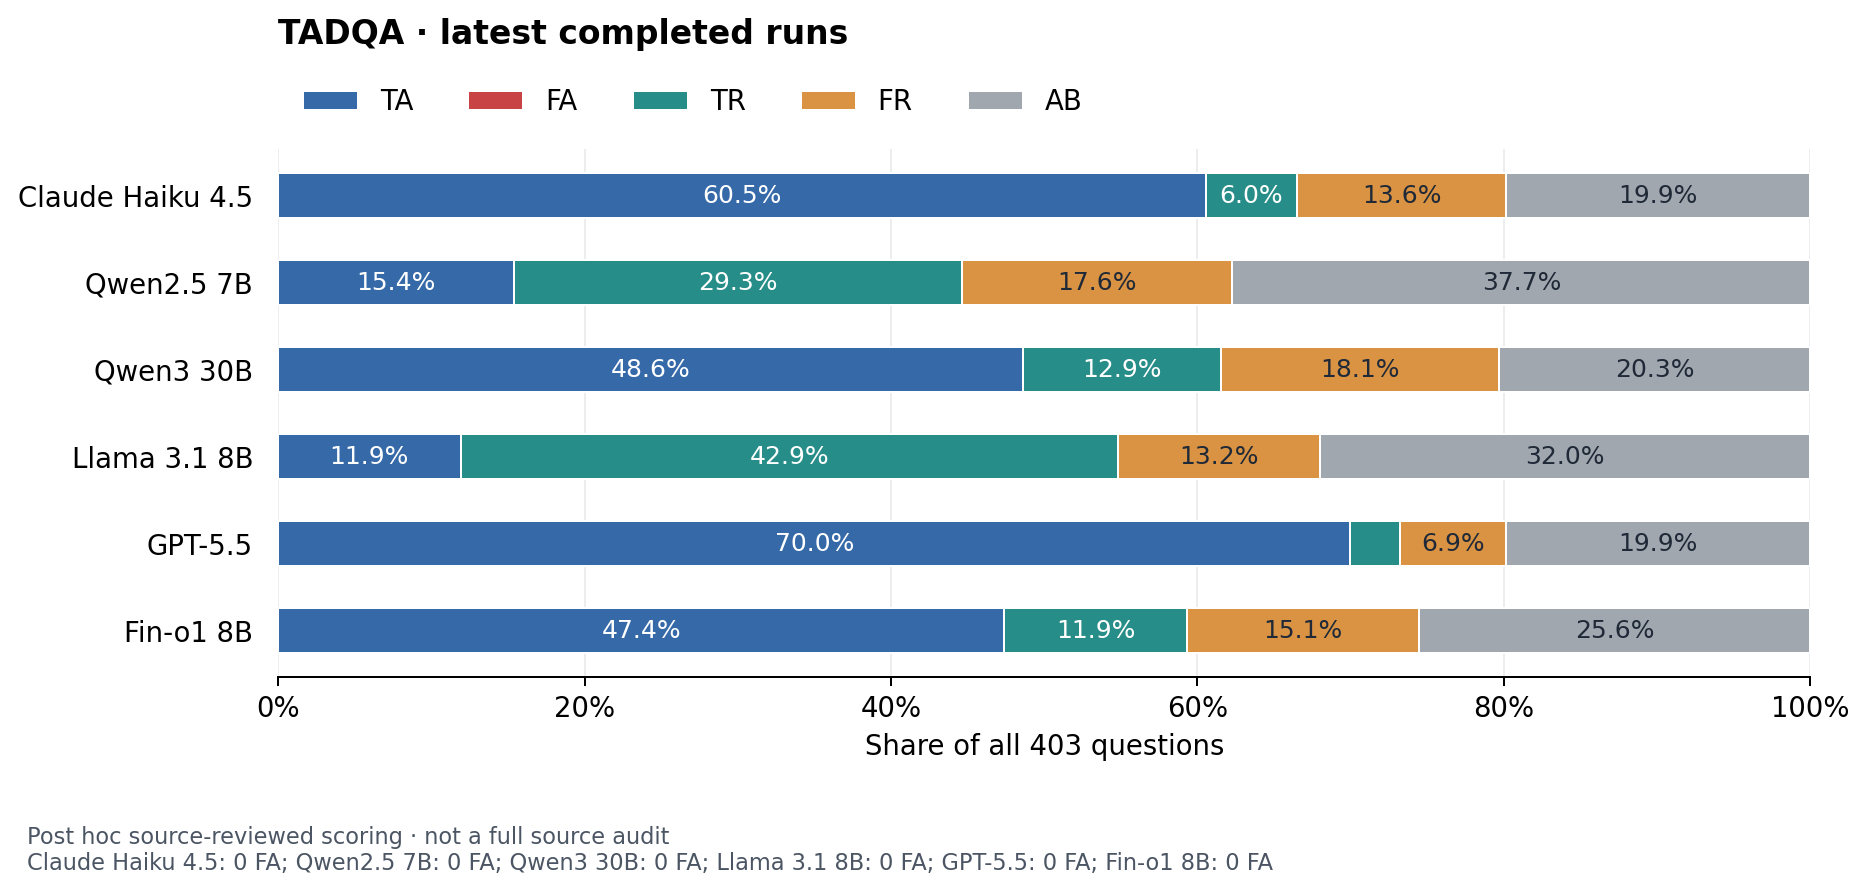

In [5]:
figure = plot_outcomes(rows)
outputs = export(ROOT, rows, provenance, figure)
# Embed the generated PNG for notebook previews, including headless execution.
display(Image(filename=str(ROOT / outputs["png"]), width=1000))
plt.close(figure)


## Definitions and traceability

The stacked figure includes complete runs only and uses all 403 questions per model, so abstentions and incorrect
rejections remain visible alongside accepted answers. Decision accuracy excludes
abstentions. The scoring labels are conditional on the existing post hoc source
annotations and are not a complete independent audit.

Exports: [table](../paper/tables/tatdqa.csv), [PNG](../paper/figures/tatdqa.png),
[PDF](../paper/figures/tatdqa.pdf), and [provenance with current input hashes](../paper/provenance/tatdqa.json).
The provenance identifies the exact result logs, evaluator inputs, annotation
hashes, and scorer code used for the displayed results.
Aggregation and plotting: [reviewer_tatdqa.py](../scripts/reviewer_tatdqa.py).

To verify the displayed results, provide the referenced result logs, dataset,
evaluator gold and annotation files, then run all cells from top to bottom.
The recorded SHA-256 hashes identify the exact inputs for comparison; the
notebook file alone does not contain all reproduction inputs.


## Qwen3 30B — source review of four false accepts

The 16 October 2026 review corrected two missing currency units, a basic-versus-diluted EPS gold-row error, and an underspecified department in a revenue-share question. The four saved answers now receive source-reviewed credit. Everbridge remains an **ambiguity adjudication**: the question does not say which of three departments it refers to.

The shared [normalizations](tatdqa_scoring_normalizations.json) and [adjudications](tatdqa_scoring_adjudications.json) apply to every model and verdict. The original benchmark gold and saved predictions are unchanged. [Audit evidence and before/after metrics](../results/new_submissions/tatdqa_qwen3_30b/false_accept_source_review.json) include source locations, hashes, and policy limitations. This review covers these four flags, not every accepted claim.


In [6]:
# Recompute the four reviewed grades from the saved Qwen claims and shared scorer.
from scripts.score_tatdqa import evaluate_run
from scripts.reviewer_tatdqa import RUNS

if provenance["runs"]["Qwen3 30B"]["state"] == "Complete":
    qwen_review = evaluate_run(ROOT, ROOT / RUNS["Qwen3 30B"])
    qwen_claims = {record["id"]: record for record in qwen_review["rows"]}
    qwen_grades = {record["id"]: record for record in qwen_review["scored_rows"]}
    qwen_findings = [
        ("tatdqa_29fbc5bd0bb36d93e810ecb557ca38b8", "Jack Henry", "1,300 USD thousands = 1.3 USD millions; missing gold scale"),
        ("tatdqa_75b650843c8490b8e97800106458054e", "NetApp", "45.24 - 37.43 = 7.81 USD/share; missing gold unit"),
        ("tatdqa_e54325bdf2794366d8cb0a710033de38", "VMware", "Diluted: 0.96 - 12.47 = -11.51 USD/share; gold used basic EPS"),
        ("tatdqa_bdf2411e367d4b93fb0247c42751491f", "Everbridge", "47 - 45 = 2 percentage points for sales and marketing; department ambiguous"),
    ]
    display(pd.DataFrame([
        {"Case": label, "Saved Qwen answer": qwen_claims[rid]["answer"],
         "Source finding": finding, "Source-reviewed grade": qwen_grades[rid]["source_reviewed_outcome"]}
        for rid, label, finding in qwen_findings
    ]).set_index("Case").style.set_properties(**{"text-align": "left", "white-space": "normal"}))
else:
    print("Qwen3 30B is pending; the four-case grade table will refresh when all 403 results are available.")


,Saved Qwen answer,Source finding,Source-reviewed grade
Case,,,
Jack Henry,1300 USD thousands,"1,300 USD thousands = 1.3 USD millions; missing gold scale",TA
NetApp,45.24 - 37.43 = 7.81 USD,45.24 - 37.43 = 7.81 USD/share; missing gold unit,TA
VMware,0.96 - 12.47 = -11.51 USD per share,Diluted: 0.96 - 12.47 = -11.51 USD/share; gold used basic EPS,TA
Everbridge,2 percentage points,47 - 45 = 2 percentage points for sales and marketing; department ambiguous,TA


## FinanceBench — latest GPT-5.5 run (67 questions)

This separate benchmark is excluded from the TADQA aggregates and confidence
intervals. The table recomputes the [saved claims](../results/new_submissions/financebench_gpt5.5/results.jsonl)
using the same [source-reviewed scorer](../src/verifiqa/eval/financebench_scoring.py)
as the CLI. [Reviewed references](../data/financebench_scoring_review.json) record
unit corrections, source arithmetic and provenance; these post hoc annotations
apply to every model and decision and do not change the saved verifier outputs.
An explicit final percentage-point literal can resolve a stored percent label;
the export records that interpretation and preserves the stored number and unit.

**FA counts graded accepts with an incorrect answer.** Precision uses `TA / (TA + FA)`;
decision accuracy uses `(TA + TR) / (TA + FA + TR + FR)`. Unresolved decisions stay
visible and are excluded from those denominators. Coverage includes all raw
VERIFIED and VIOLATED decisions. The precision bounds below assign unresolved
accepts first as incorrect, then as correct; they are **not confidence intervals**.

The PepsiCo restructuring question (`financebench_id_01328`) permits conflicting
presentation and economic-total readings (0 versus $411 million). Candidates matching
either reading are unresolved; other amounts remain gradeable. A separate historical [source audit](../artifacts/financebench_abstention_audit/latest_codex_source_audit.json)
documents a wrong-subset XBRL binding in its pinned run. The calculated audit
note below reports whether the current run matches that snapshot. Per-question scores and input hashes are exported to
`artifacts/financebench_notebook_latest/`.


In [7]:
# Calculate scores from frozen claims; summary.json and cached grades are unused.
import hashlib
import importlib
import json
from IPython.display import Markdown
from scripts.reviewer_tatdqa import latest_run_state

financebench_scoring = importlib.reload(importlib.import_module("verifiqa.eval.financebench_scoring"))
financebench_paths = {
    "dataset": "data/numerical_questions.jsonl",
    "results": "results/new_submissions/financebench_gpt5.5/results.jsonl",
    "manifest": "results/new_submissions/financebench_gpt5.5/run_manifest.json",
    "review": "data/financebench_scoring_review.json",
    "scorer": "src/verifiqa/eval/financebench_scoring.py",
    "candidate_scorer": "src/verifiqa/eval/candidate_scoring.py",
    "unit_conversion": "src/verifiqa/verification/money_units.py",
}
financebench_table = None
financebench_result_path = ROOT / financebench_paths["results"]
if not financebench_result_path.is_file():
    print("FinanceBench: Pending 0/67; no metrics calculated or exported.")
else:
    financebench_scorer = financebench_scoring.FinanceBenchScorer.from_root(ROOT)
    financebench_ids = set(financebench_scorer.dataset)
    financebench_state = latest_run_state(
        ROOT, financebench_result_path.parent, financebench_ids, allow_incomplete=True)
    if financebench_state["state"] == "Pending":
        print(f"FinanceBench: Pending {financebench_state['progress']}; no metrics calculated or exported.")
    else:
        if not (ROOT / financebench_paths["manifest"]).is_file():
            raise ValueError("Selected GPT-5.5 FinanceBench run is missing its manifest")
        financebench_hashes = {name: hashlib.sha256((ROOT / path).read_bytes()).hexdigest()
                              for name, path in financebench_paths.items()}
        financebench_records = [json.loads(line) for line in financebench_result_path.read_text().splitlines()
                                if line.strip()]
        financebench_manifest = json.loads((ROOT / financebench_paths["manifest"]).read_text())
        financebench_metadata = financebench_manifest.get("llm_run", {})
        financebench_settings = financebench_manifest.get("settings", {})
        if (financebench_metadata.get("model") != "gpt-5.5"
                or financebench_metadata.get("mode") != "openai"
                or financebench_settings.get("model") != "gpt-5.5"
                or financebench_settings.get("mode") != "openai"
                or financebench_settings.get("claim_source") != "generated_answer"
                or financebench_settings.get("deterministic_smt") is not True
                or any(row.get("llm_run") != financebench_metadata for row in financebench_records)
                or any("baseline" in row for row in financebench_records)):
            raise ValueError("Selected FinanceBench run does not identify the GPT-5.5 verification pipeline")
        financebench_summary = financebench_scorer.summarize_rows(financebench_records)
        financebench_scores = financebench_scorer.score_rows(financebench_records)
        financebench_authority = financebench_scorer.authority_audit(financebench_result_path)
        financebench_counts = {key: financebench_summary[key] for key in
            ("TA", "FA", "TR", "FR", "AB", "UNSCORED_VERIFIED", "UNSCORED_REJECTED")}
        assert sum(financebench_counts.values()) == len(financebench_ids) == 67
        financebench_table = pd.DataFrame([{
            "Scoring": "Source reviewed (post hoc)", "Total": financebench_summary["total"],
            "VERIFIED": financebench_summary["verified"], "VIOLATED": financebench_summary["violated"],
            "ABSTAIN": financebench_summary["abstain"],
            **{key: financebench_summary[key] for key in ("TA", "FA", "TR", "FR")},
            "Unscored VERIFIED": financebench_summary["unscored_verified"],
            "Unscored VIOLATED": financebench_summary["unscored_rejected"],
            "Precision": financebench_summary["verification_precision"],
            "Decision accuracy": financebench_summary["decision_accuracy"],
            "Coverage": financebench_summary["coverage"],
        }]).set_index("Scoring")
        display(financebench_table.style.format({
            **{name: "{:.0f}" for name in financebench_table.columns
               if name not in ("Precision", "Decision accuracy", "Coverage")},
            **{name: "{:.2%}" for name in ("Precision", "Decision accuracy", "Coverage")},
        }).set_caption("FinanceBench · GPT-5.5 · source reviewed; precision and accuracy use graded decisions"))
        financebench_graded_accepts = financebench_summary["TA"] + financebench_summary["FA"]
        financebench_bounds = financebench_summary["precision_bounds"]
        display(Markdown(
            f"**Confirmed FA: {financebench_summary['FA']}.** "
            f"Precision: **{financebench_summary['TA']}/{financebench_graded_accepts}** graded accepts; "
            f"**{financebench_summary['unscored_verified']} of {financebench_summary['verified']}** "
            f"raw accepts unresolved. All-acceptance precision bounds: "
            f"**{financebench_bounds[0]:.2%}–{financebench_bounds[1]:.2%}** (not a confidence interval). "
            f"Decision accuracy: **{financebench_summary['TA'] + financebench_summary['TR']}/"
            f"{financebench_summary['scored_decisions']}** graded decisions."))
        display(Markdown(financebench_authority["display_note"]))
        financebench_outcomes = [{
            "id": record["id"], "status": record["status"],
            "claimed_value": record.get("claimed_value"),
            "claimed_value_unit": record.get("claimed_value_unit", ""),
            "gold_answer": record["raw_answer"],
            "source_reviewed_outcome": score["outcome"],
            "source_reviewed_candidate_correct": score["candidate_correct"],
            "reason": score["reason"], "reference_targets": json.dumps(score["reference_targets"]),
            "comparison_claim_unit": score["comparison_claim_unit"],
            "unit_interpretation": json.dumps(score["unit_interpretation"]),
        } for record, score in zip(financebench_records, financebench_scores)]
        if (financebench_hashes["results"] != financebench_state["sha256"] or
                any(hashlib.sha256((ROOT / path).read_bytes()).hexdigest() != financebench_hashes[name]
                    for name, path in financebench_paths.items())):
            raise ValueError("FinanceBench inputs changed during scoring; rerun this cell")
        financebench_export = ROOT / "artifacts/financebench_notebook_latest"
        financebench_export.mkdir(parents=True, exist_ok=True)
        financebench_table.to_csv(financebench_export / "results_table.csv")
        pd.DataFrame(financebench_outcomes).to_csv(financebench_export / "scored_rows.csv", index=False)
        (financebench_export / "provenance.json").write_text(json.dumps({
            "dataset": "FinanceBench", "questions": len(financebench_ids),
            "models": sorted({row.get("llm_run", {}).get("model", "unspecified")
                              for row in financebench_records}),
            "included_in_tadqa_aggregates": False,
            "scoring": financebench_summary["scoring"], "authority_audit": financebench_authority,
            "input_files": {name: {"path": path, "sha256": financebench_hashes[name]}
                            for name, path in financebench_paths.items()},
            "counts": financebench_counts,
            "precision_denominator": "TA + FA", "accuracy_denominator": "TA + FA + TR + FR",
            "raw_verified": financebench_summary["verified"],
            "graded_verified": financebench_graded_accepts,
            "precision_bounds": financebench_bounds,
        }, indent=2) + "\n")


,Total,VERIFIED,VIOLATED,ABSTAIN,TA,FA,TR,FR,Unscored VERIFIED,Unscored VIOLATED,Precision,Decision accuracy,Coverage
Scoring,,,,,,,,,,,,,
Source reviewed (post hoc),67,35,12,20,34,0,5,6,1,1,100.00%,86.67%,70.15%


**Confirmed FA: 0.** Precision: **34/34** graded accepts; **1 of 35** raw accepts unresolved. All-acceptance precision bounds: **97.14%–100.00%** (not a confidence interval). Decision accuracy: **39/45** graded decisions.

Grounding defects have not been audited for this run.